## Long Step

In [1]:
%load_ext autoreload
%autoreload 1

#%aimport quantdata
#%aimport quantdata.biz_calendar
#%aimport quantdata.widb
#%aimport quantdata.widb.client
#%aimport quantdata.widb.day
#%aimport quantdata.widb.arbfree
#%aimport quantdata.widb.options_filter
#%aimport quantdata.utils.backbone
#%aimport quantdata.sanos.sanos_tools
#%aimport quantdata.sanos.arbfree
#%aimport quantdata.sanos.sanos
#%aimport quantdata.dysanos
%aimport quantdata.dysanos.grid.torch_market
%aimport quantdata.dysanos.grid.torch_pricer
%aimport quantdata.dysanos.grid.torch_model
%aimport quantdata.dysanos.grid.torch_gfx 
%aimport quantdata.dysanos.grid.torch_train 
%aimport quantdata.dysanos.grid.torch_simulator
%aimport quantdata.dysanos.grid.torch_universe
%aimport quantdata.dysanos.grid.torch_drift_change
%aimport quantdata.dysanos.grid.torch_det_measure_change
%aimport quantdata.dysanos.grid.torch_all

from quantdata.dysanos.grid.torch_market import GridMarketDefinition, DateRange, PoolConfig, Context, date, GridConfig
from quantdata.dysanos.grid.torch_all import run_experiment, DysanosExperiment
import gc

market = None
gc.collect()

# load market data
# ----------------

experiment = DysanosExperiment()

print("** Starting to load market data...")
grid_config     = GridConfig(grid_num_strikes=experiment.grid_strikes)
grid_market_def = GridMarketDefinition( ticker="SPX", date_range=DateRange(start=date(2020, 1, 1), end=date(2025, 8, 30)), grid_config=grid_config )
market          = grid_market_def.load( pool_config = PoolConfig(num_workers=4, threading=False ), override_cache_mode="cacheonly", verbose=Context.all )
print(f"nms /done - found {len(market['dates'])} dates.")

** Starting to load market data...
nms /done - found 1412 dates.


In [2]:

from quantdata.dysanos.grid.torch_all import run_experiment, DysanosExperiment

from dataclasses import dataclass, asdict
import gc
from cdxcore.pretty import PrettyObject
from cdxcore.verbose import Context
import numpy as np
from quantdata.dysanos.grid.torch_simulator import plot_sampler


# load trained model
# ------------------

from quantdata.pool import PoolConfig
from quantdata.dysanos.grid.torch_gfx import VizConfig
from quantdata.dysanos.grid.torch_train import train, TrainConfig
from quantdata.dysanos.grid.torch_model import BaseEnvironment, FeedForward, SanosModelConfig, SanosDecoderConfig

mdl_config = SanosModelConfig( 
    label="ac_state20",
    user_version="0.2",
    group="sm25_100",
    encoder_config = FeedForward.Config(
            activation = "SELU",
            num_depth = 2,
            num_width = 100,
            use_bias = True,
        ),
    decoder_config = SanosDecoderConfig(
        smoothness = 0.25,
        num_state = 20, 
        nn_config = FeedForward.Config(
            activation = "SELU",
            num_depth = 2,
            num_width = 100,
            use_bias = True,
        ),
    ),
)

model        = None
torch_data   = None
env          = BaseEnvironment(device="cpu", debug=False)
viz_config   = VizConfig( num_viz_dates=4 )
trn_config   = TrainConfig( num_epochs=100_000, lr=1E-4, final_lr=1E-6, weight_decay=1e-4, batch_size=400, compile=True, epoch_interval=10000 )
print("Loading trained model...")
model_output,\
model,\
torch_data   = train( market, mdl_config=mdl_config, trn_config=trn_config, viz_config=viz_config, just_load="plot", env=env )
torch_data   = mdl_config.torch_data( env = env, market = market, verbose = Context.quiet ) if torch_data is None else torch_data
del model_output, mdl_config, viz_config, env
gc.collect()
print("Trained model loaded.")


Loading trained model...
Trained model loaded.


Computing AR1(1) PCA
00: Model ac_state20@sm25_100 0.2: using 10 factors for 21 states (incl. spot) over 1412 dates. The 10 factors explain 99.7% of variance.


C:\Users\hans\OneDrive\Python3\quant_data\quantdata\dysanos\grid\torch_simulator.py:725: UserWarning: Continuous-time OU calibration stopped before the optimizer's convergence criterion (STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT); using the best stable iterate after 100 iterations with objective 0.0994116.


AR(1) PCA computed:
alpha mean: [ 8.00603776e-17  9.39184945e-17 -3.22602013e-18  4.56560532e-17
 -1.52852374e-16 -3.19848093e-17  1.88643494e-17  3.47436467e-17
 -6.43187763e-17 -1.36619002e-16]
min real eigenvalue(k): 0.04670929330921157
max Euler transition spectral radius: 7319.68142466364
max matrix-exp transition spectral radius: 0.9547096943748925
u0 [[-4.81524904e-01  5.15714984e+03  1.29073076e+03 -5.47598991e+02
   1.15309280e+03 -8.67195002e+02  1.41826284e+03  1.68945485e+02
  -6.15737444e+01  6.42583208e+02 -1.25882627e+01  3.59622313e+02
   4.32477066e+03 -7.48374505e+02 -1.73687228e+02 -4.82758762e+02
  -2.18789912e+02 -1.28932621e+03 -5.24213293e+02 -6.22933099e+02
   1.39926650e+03]]


## ac_state20@sm25_100 0.2: using 10 Alphas for 21 Extended States

### Real and simulated states, discrete to normal randomness

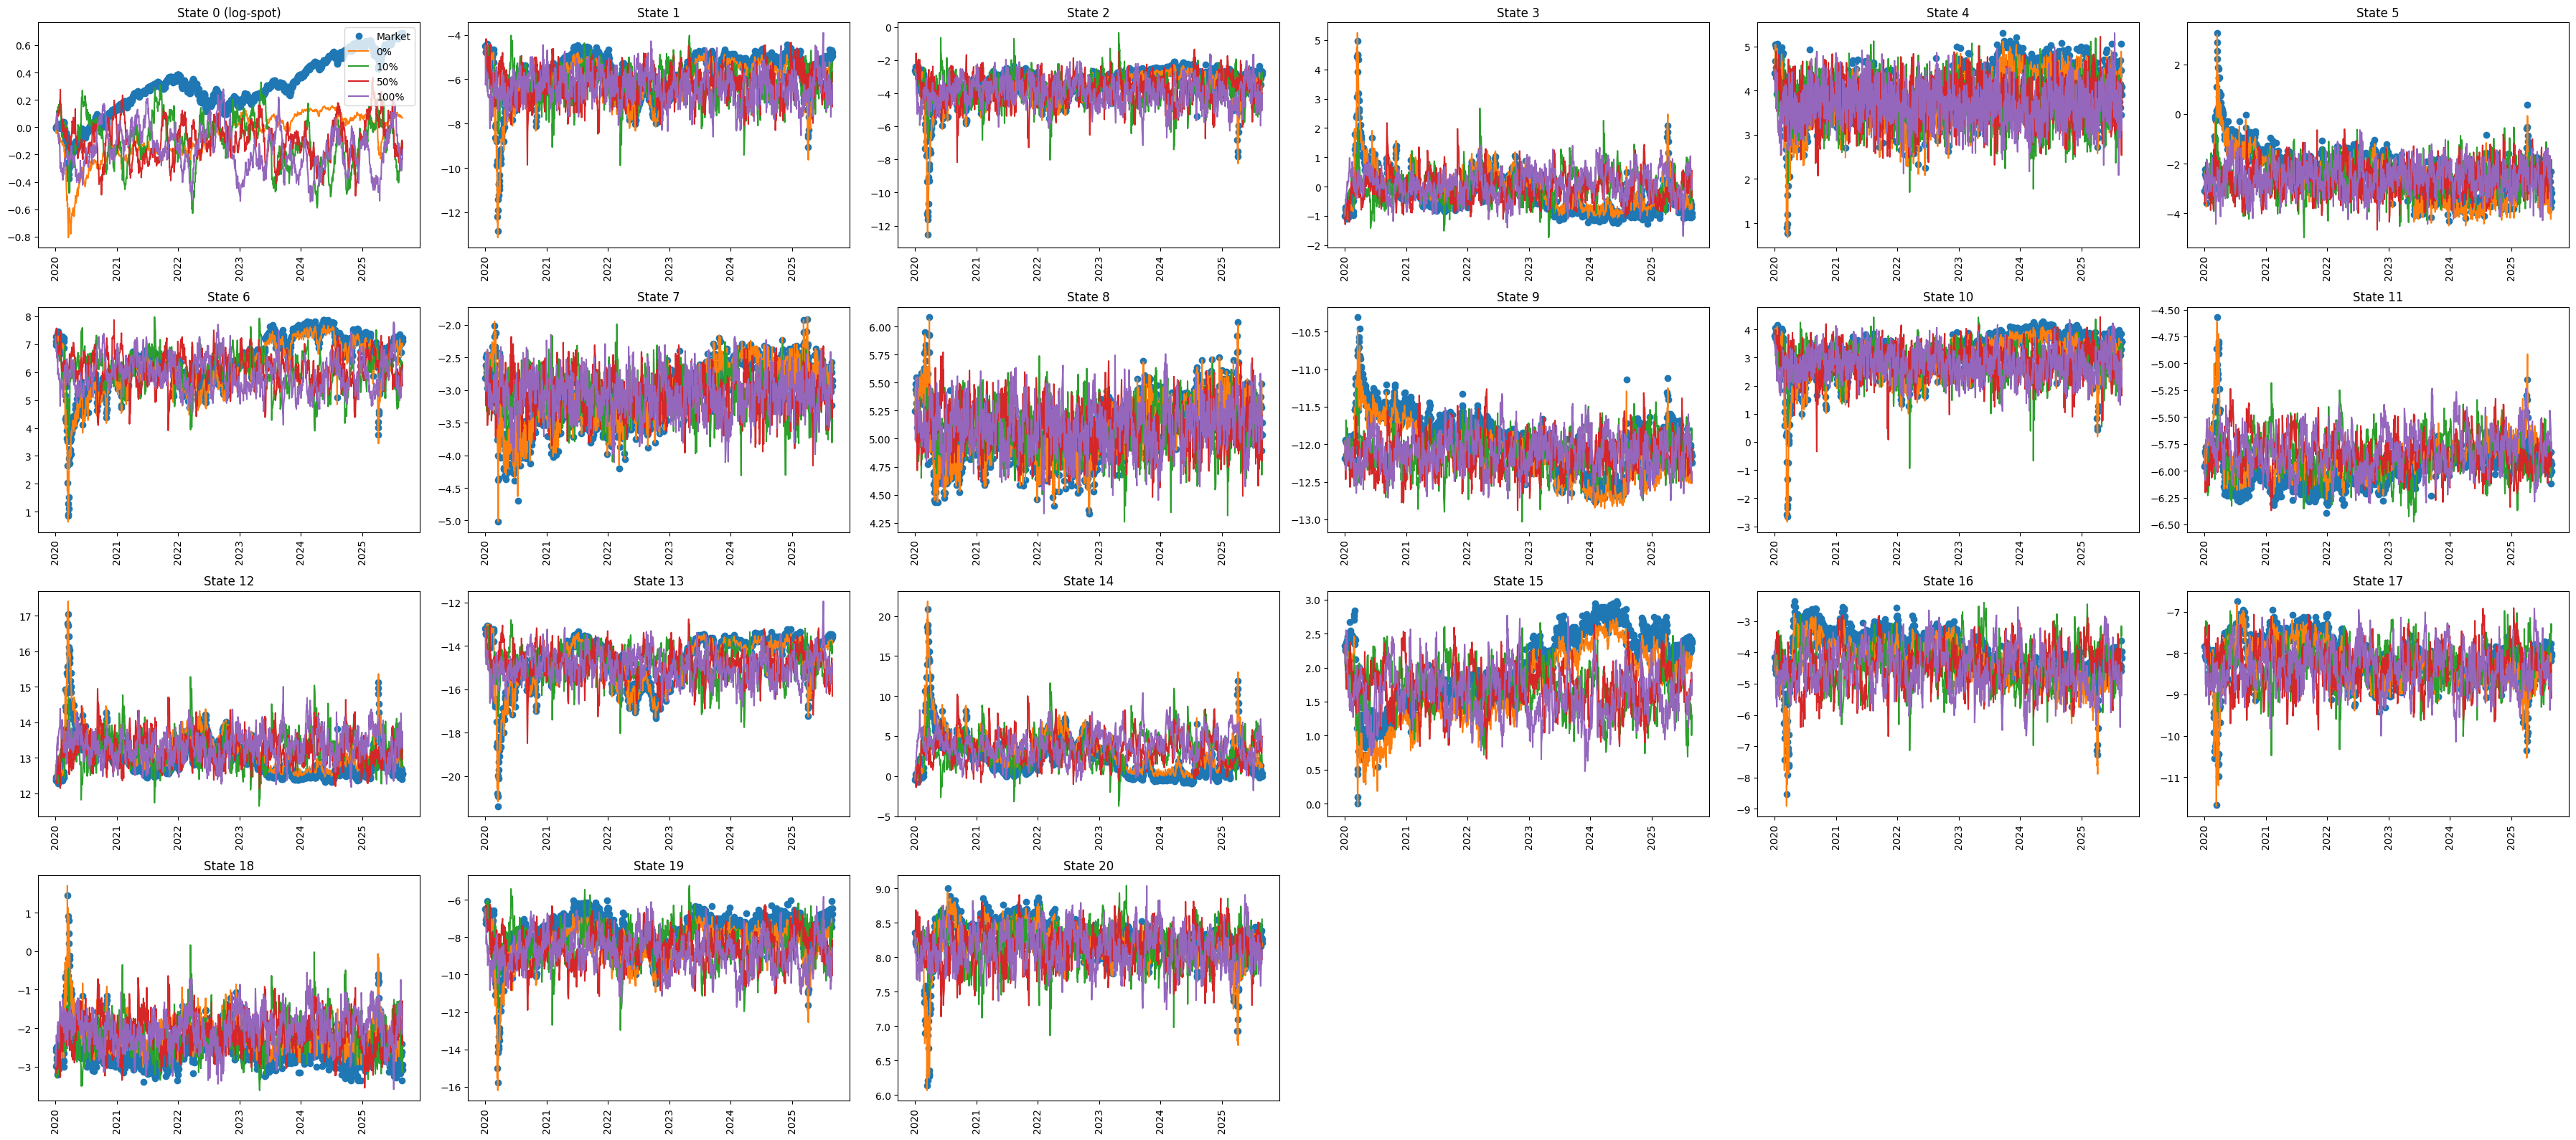

### ac_state20@sm25_100 0.2 factors

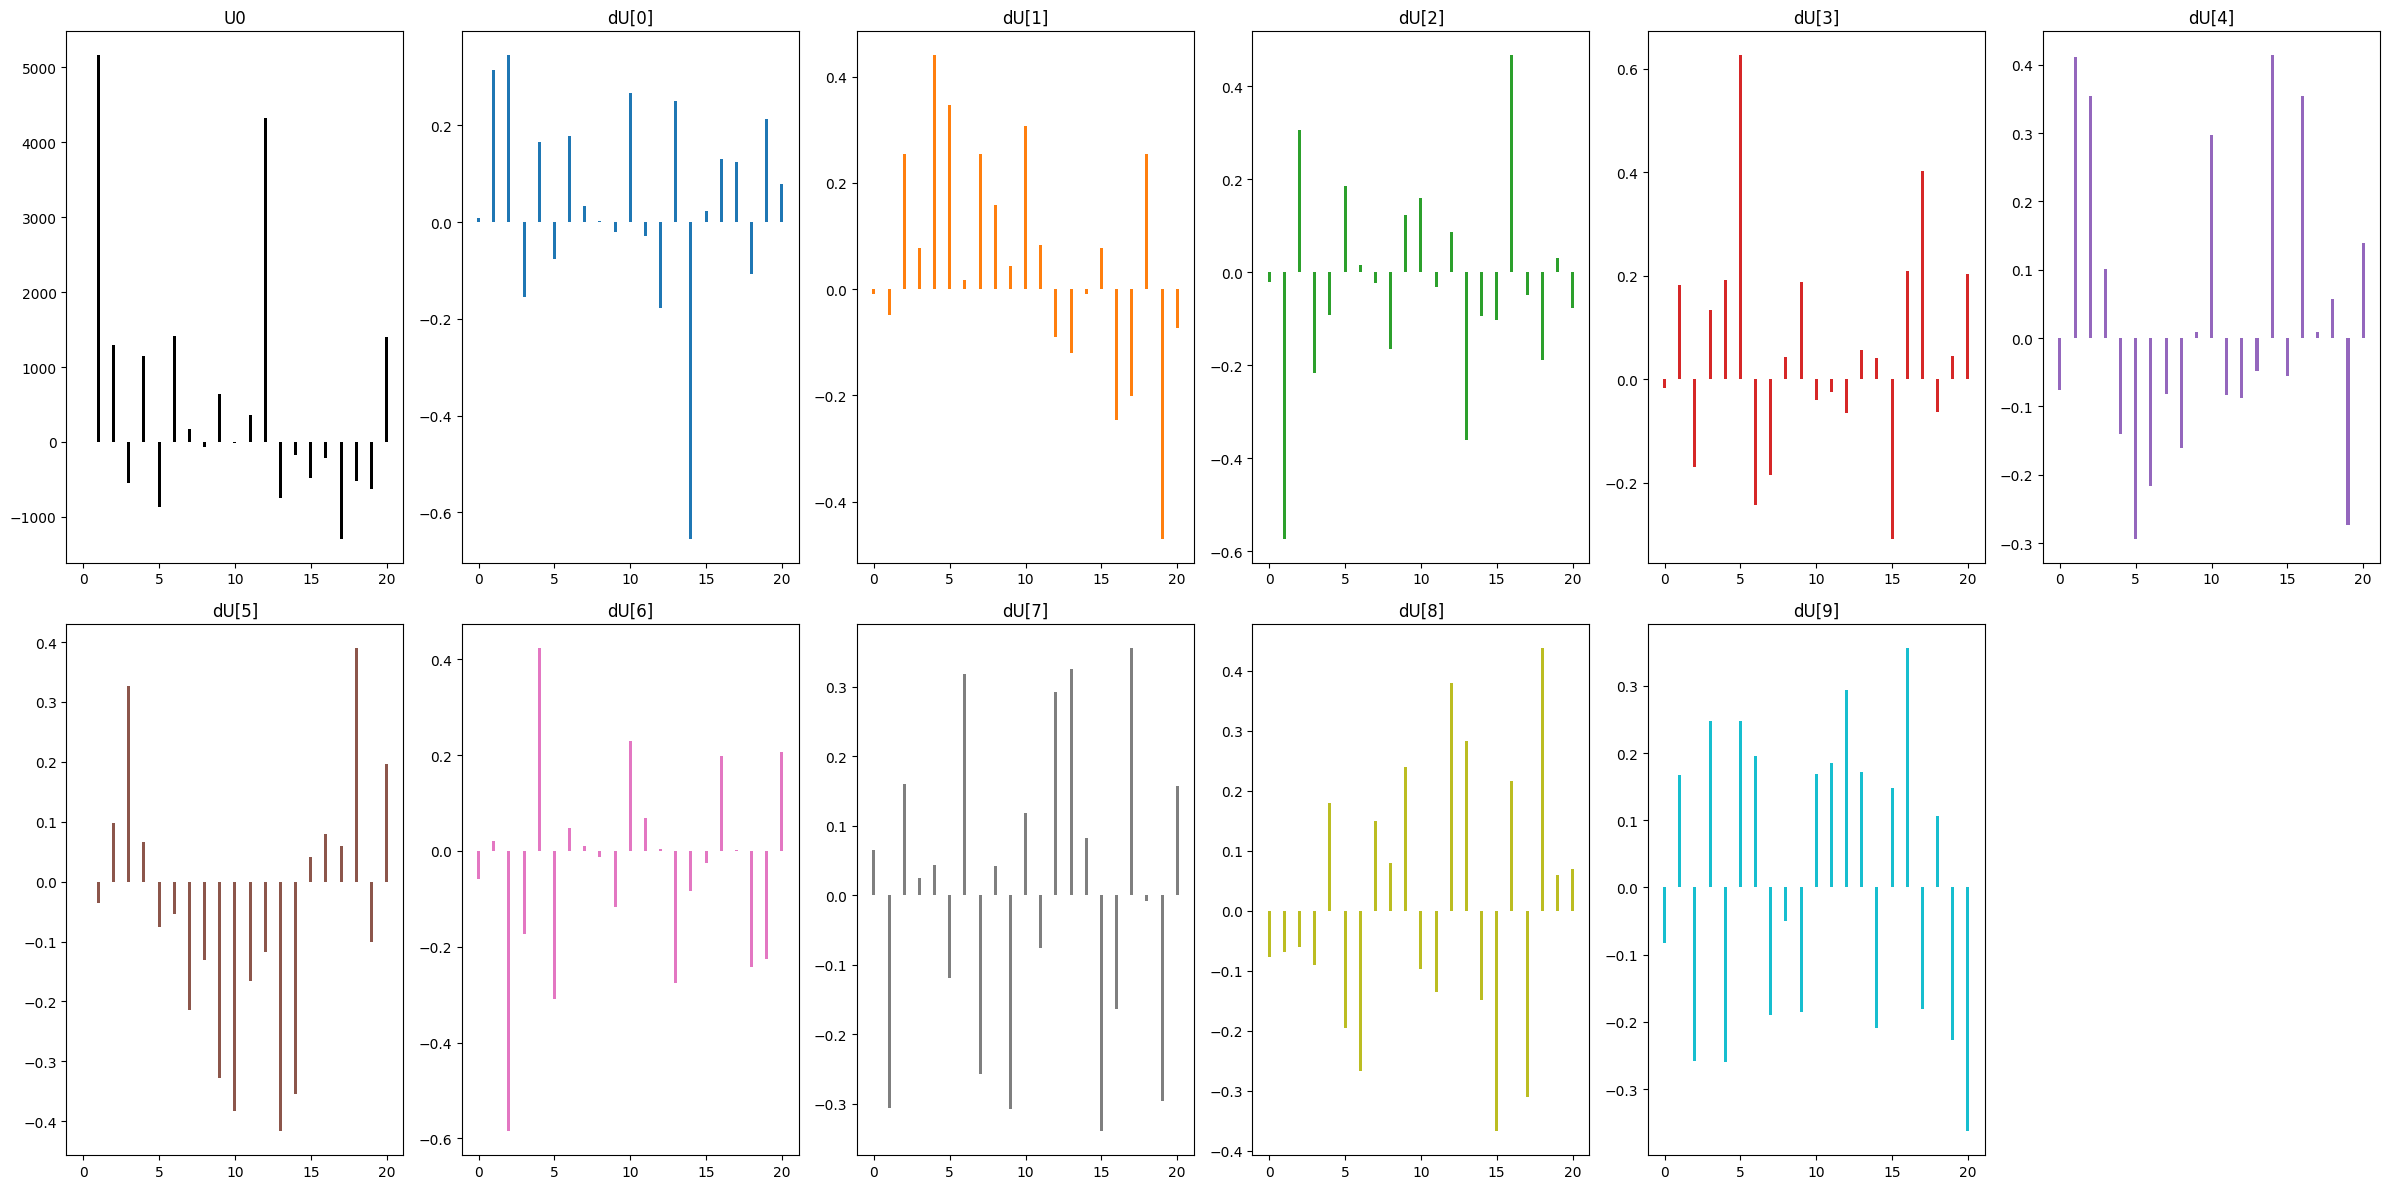

### ac_state20@sm25_100 0.2 weights

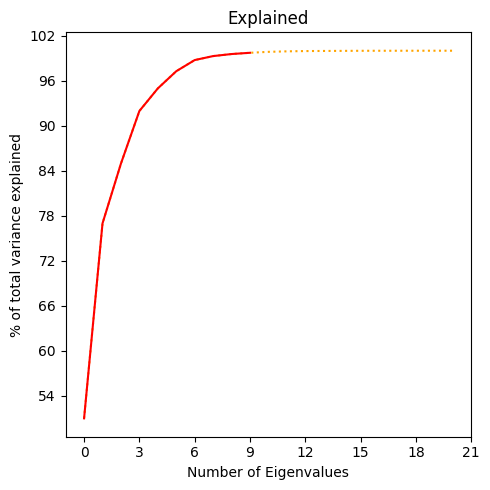

### ac_state20@sm25_100 0.2 weights

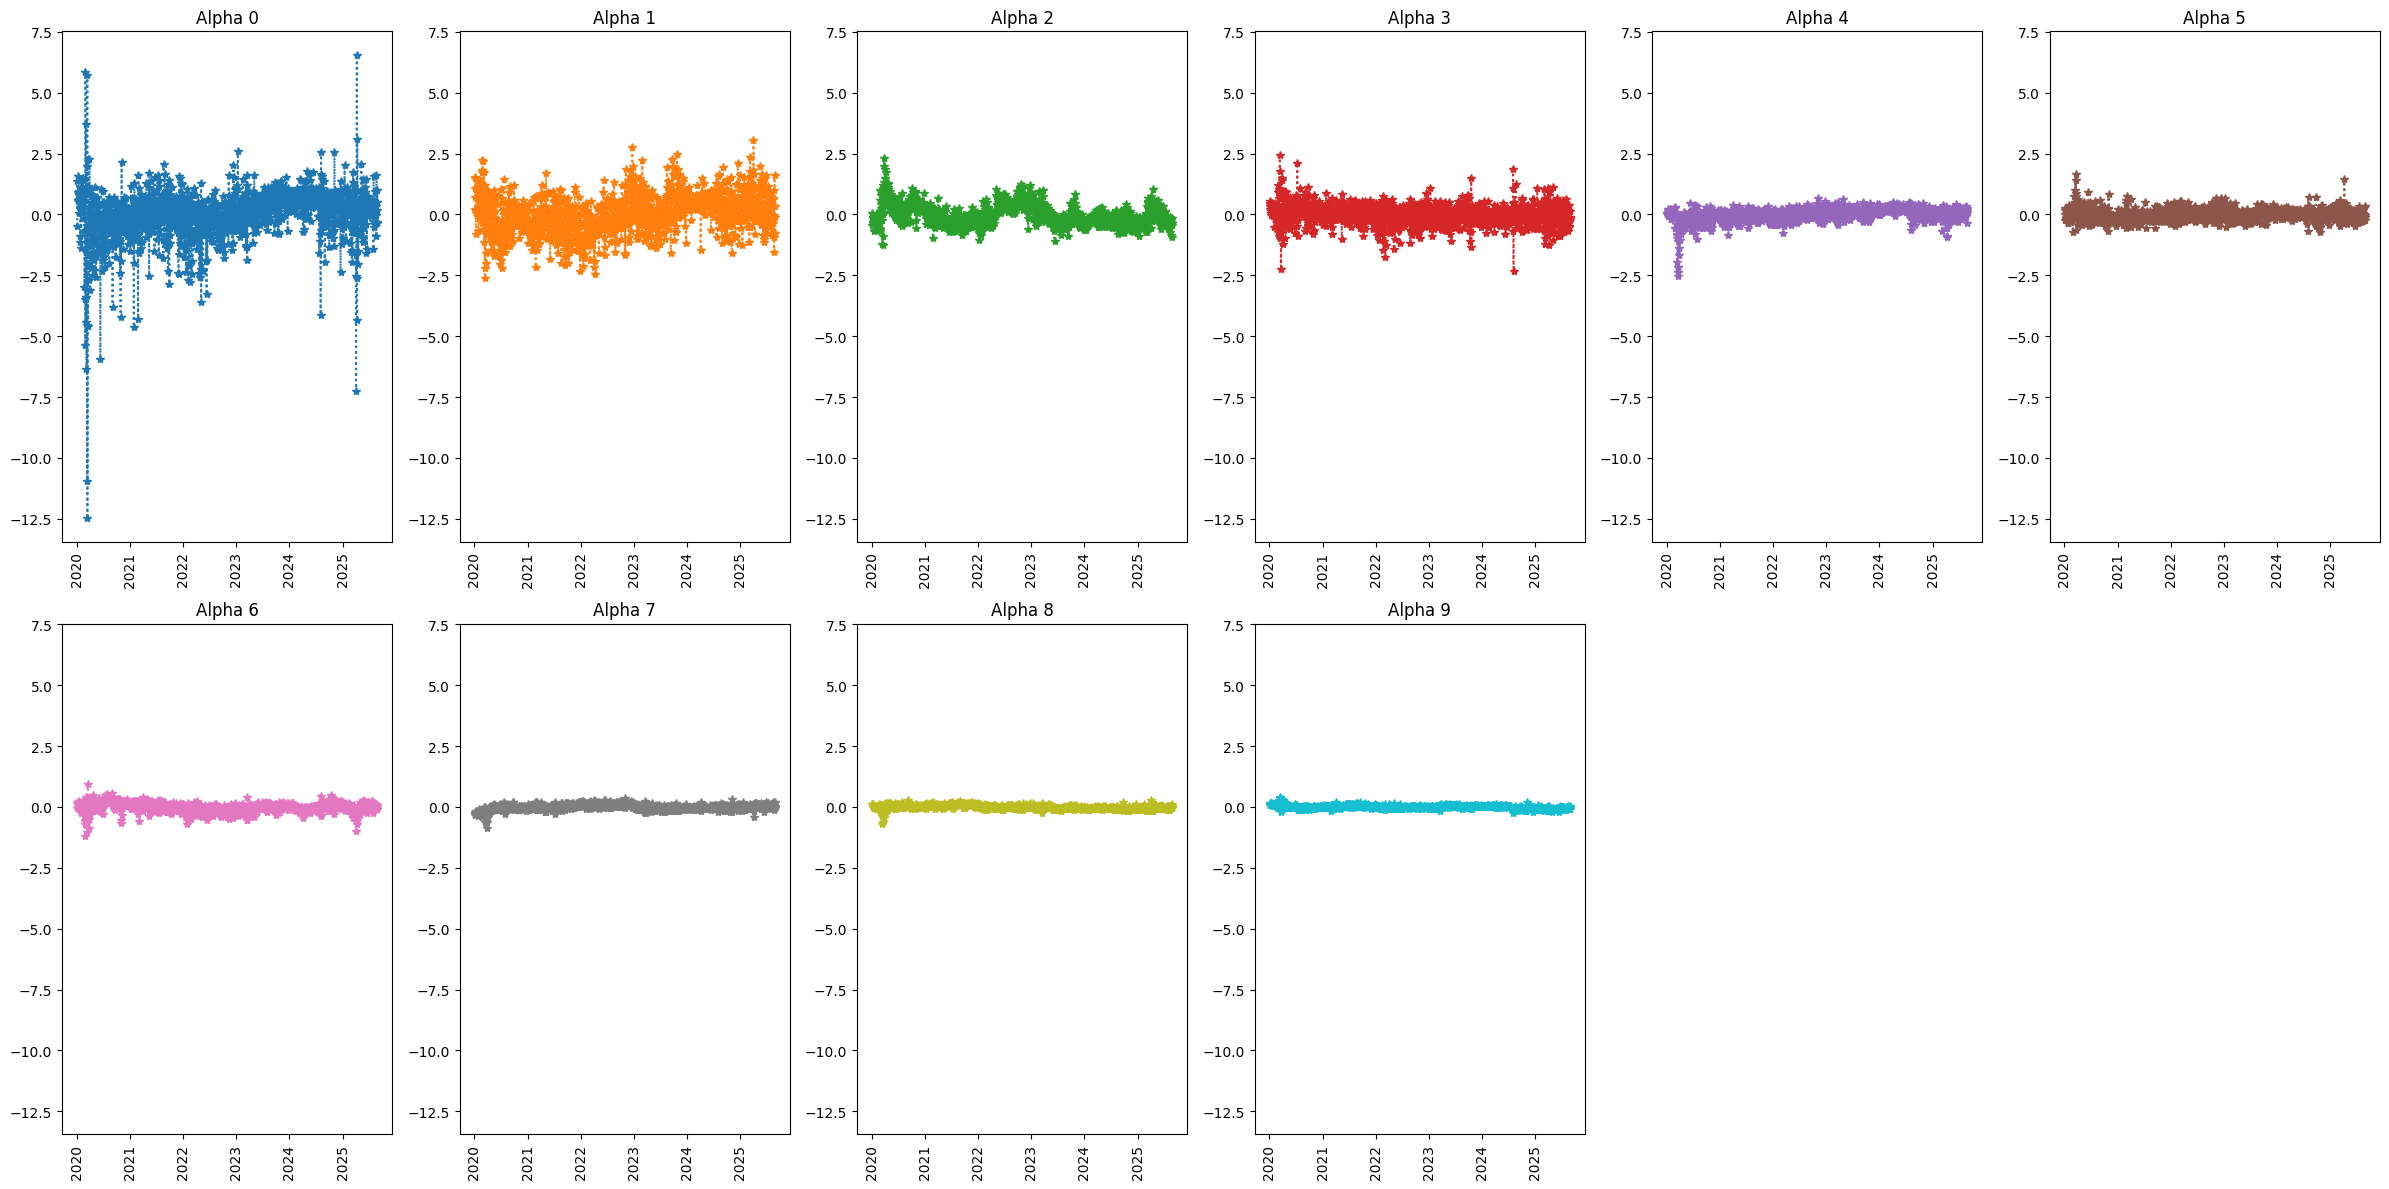

566

In [3]:

# AR(1) PCA
# --------=-

from quantdata.dysanos.grid.torch_simulator import ARSamplerConfig, ARSampler, Context, plot_sampler as plot_ar_sampler

print("Computing AR1(1) PCA")
ar_config      = ARSamplerConfig(num_alpha=10, use_matrix_exp=True)
sampler        = ARSampler( market, model, torch_data, config=ar_config, verbose=Context.all )
gc.collect()
print("AR(1) PCA computed:")
sampler.report_system()

if plot_sampler:
    plot_ar_sampler(sampler)

gc.collect()



In [5]:
gc.collect()

def mk_long_universe():
    from quantdata.dysanos.grid.torch_universe import create_universe, DAYS_PER_YEAR
    print("Simulating universe")
    universe = create_universe( model=model, sampler=sampler, market=market, reset_rng=True,
                               num_steps=10,
                               num_samples=100,
                               bandwidth=1.,
                               dt=1.,
                               price_dt=False,
                               block_size=1000,)
    gc.collect()
    print("Simulated universe")
    for k,v in universe.items():
        if v is None:
            continue
        if isinstance(v, np.ndarray):
            print( k, v.shape, v.nbytes, v.dtype, "ok" if np.all(np.isfinite(v)) else f"** {np.sum(np.isfinite(v))}")
        else:
            print( k, v )

    return universe

universe = mk_long_universe()


Simulating universe
00: Generating 100 samples of ac_state20@sm25_100 0.2 for 10 steps... generated state of size 82.03KB; now building market:
01:   Created paths of 100 samples over 10 time steps: this took 0.74s
00: Generated universe; this took 0.75s. Using 3449.22KB equal to 34.49KB per sample.
Simulated universe
C_t (100, 9, 7, 20) 504000 float32 ok
strikes_t (100, 9, 7, 20) 504000 float32 ok
spots (100, 10) 4000 float32 ok
vols_t (100, 9, 7, 20) 504000 float32 ok
delta_t (100, 9, 7, 20) 504000 float32 ok
vega_t (100, 9, 7, 20) 504000 float32 ok
gamma_t (100, 9, 7, 20) 504000 float32 ok
theta_t (100, 9, 7, 20) 504000 float32 ok
xstate (100, 10, 21) 168000 float64 ok
dt 1.0
bandwidth 1.0
expiries (7,) 56 float64 ok


In [ ]:
gc.collect()
